# データサイエンス実践A 第11講：伝わるグラフ・総復習の演習
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月13日（金）**

1. 最初に、**誤解を招くグラフ**の例を正しい描き方と並べて見て、**伝わるグラフ**のチェックリストを確かめる（AT）。
1. 残りの時間は、CES-Alpha の演習「第11講」（12問）で、ここまでのグラフを総復習する（AU）。
1. 第２回課題（締切 11/16）で困っているところは、この時間に質問する。
1. エラーが出たら、**よくあるエラー**の表（AF）で原因を探す。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AT. 伝わるグラフ・誤解を招くグラフ](#AT.-伝わるグラフ・誤解を招くグラフ)**
- [AT-1 縦軸を途中から始めた棒グラフ](#AT-1-縦軸を途中から始めた棒グラフ)
- [AT-2 項目が多すぎる円グラフ](#AT-2-項目が多すぎる円グラフ)
- [AT-3 第３回課題に向けたチェックリスト](#AT-3-第３回課題に向けたチェックリスト)

**[AU. 総復習の演習](#AU.-総復習の演習)**
- [AU-1 演習のデータ](#AU-1-演習のデータ)
- [AU-2 演習の一覧](#AU-2-演習の一覧)
- [AU-3 グラフの型の一覧](#AU-3-グラフの型の一覧)
- [AU-4 共通の指定](#AU-4-共通の指定)

**[AF. よくあるエラーと対処](#AF.-よくあるエラーと対処)**

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は、画像や記号をマーカーにした**遊び心のあるグラフ**を描いた
- `plt.subplot(縦の数, 横の数, 何番目)` で、複数のグラフを並べた
- 第２回課題の締切は 11/16（月）。今日の演習に、課題で使うグラフ（円・箱ひげ図・複合グラフ・エラーバー）も入っている

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

---
# AT. 伝わるグラフ・誤解を招くグラフ

ここまでのグラフを、「見る人に正しく伝わるか」という目で見直す。よくある失敗を、正しい描き方と並べて見る（並べ方は第10講 AI-1 の `plt.subplot`）。

## AT-1 縦軸を途中から始めた棒グラフ

- 左は 90 から始めているので、A と B の差が何倍にも見える。**棒グラフの縦軸は 0 から**

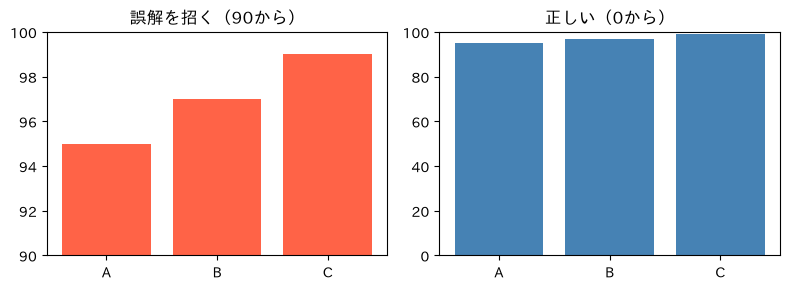

In [2]:
names = ['A', 'B', 'C']
values = [95, 97, 99]

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.bar(names, values, color='tomato')
plt.ylim(90, 100)
plt.title('誤解を招く（90から）')

plt.subplot(1, 2, 2)
plt.bar(names, values, color='steelblue')
plt.ylim(0, 100)
plt.title('正しい（0から）')
plt.tight_layout()
plt.show()

- 棒グラフは「棒の長さ」で大きさを比べる。途中から始めると、長さの比が実際の値の比と合わなくなる
- 折れ線グラフは「変化」を見るので、途中から始めてもよい（ただし軸の数字ははっきり書く）

## AT-2 項目が多すぎる円グラフ

- 項目が多いと、小さい扇形が読めなくなる。**5つくらいまで**にして、残りは「その他」にまとめる

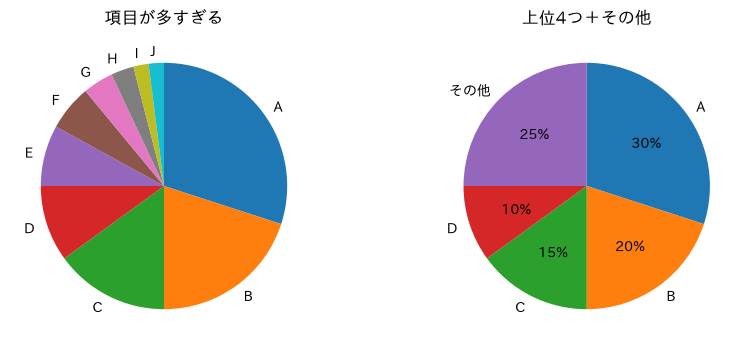

In [3]:
names = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
values = [30, 20, 15, 10, 8, 6, 4, 3, 2, 2]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.pie(values, labels=names, startangle=90, counterclock=False)
plt.title('項目が多すぎる')

plt.subplot(1, 2, 2)
plt.pie(values[:4] + [sum(values[4:])], labels=names[:4] + ['その他'],
        autopct='%1.0f%%', startangle=90, counterclock=False)
plt.title('上位4つ＋その他')
plt.show()

- `values[:4]` は前から4つ、`values[4:]` は5つ目から最後まで（リストの切り出し）。`sum()` で合計する

## AT-3 第３回課題に向けたチェックリスト

| よくある失敗 | どうする |
|---|---|
| 棒グラフの縦軸が 0 から始まっていない | `plt.ylim(0, …)` |
| 立体（3D）の円グラフ | 手前が大きく見える。平らな円グラフか棒グラフにする |
| 項目が多すぎる円グラフ | 5つくらいまで。残りは「その他」にまとめる |
| 軸の名前・単位がない | `plt.xlabel`・`plt.ylabel` に単位まで書く（例：`'降水量 (mm)'`） |
| 色が多すぎる・赤と緑で区別している | 色は意味のあるところだけ。赤と緑は見分けにくい人がいるので、青とオレンジなどにする |
| 凡例がなく、どの線が何か分からない | `label=` ＋ `plt.legend()` |
| 文字が小さくて読めない | `fontsize=14` など。スライドに貼るなら大きめに |
| データの出どころが書いていない | 図の下や説明文に「出典：e-Stat ○○統計」などと書く |
| 画像やイラストでデータが読みにくい | 遊び心（第10講 AH）は**データが読める範囲で** |

> **第３回課題に向けて**：自分のグラフで、この表を1つずつ確かめる

---
# AU. 総復習の演習

## AU-1 演習のデータ

- 演習は、総復習用の Excel `dsa2026review.xlsx` を使う
- ある大学のカフェの 2025 年のデータ（架空）。シートは3つある

| シート | 中身 |
|---|---|
| `cafe` | 月ごとの平均気温・来客数・前年来客数・店内・テイクアウト・ホット・アイス・本店売上・駅前店売上 |
| `cafe_menu` | メニューごとの杯数 |
| `cafe_week` | 20週分の、曜日（月〜金）ごとの1日の来客数 |

- ファイルは GitHub に置いてある。URL は次のとおり

```
https://raw.githubusercontent.com/CreativeStudies-NGT/lectures/main/dsa/dsa2026review.xlsx
```

### 自分の PC の Anaconda（Jupyter Notebook）で使うとき

ファイルを notebook と同じ場所（いつもの場所）に置く。方法は2つある。

**[1] ブラウザでダウンロードする**
- 上の URL をブラウザで開くと、`dsa2026review.xlsx` がダウンロードされる
- ダウンロードフォルダ（Windows はエクスプローラー、Mac は Finder で開く）から、いつもの場所に移す

**[2] notebook のセルでダウンロードする**
- 新しいセルに次の1行を書いて実行すると、いつもの場所にダウンロードされる（Windows・Mac とも同じ）

```python
!curl -O https://raw.githubusercontent.com/CreativeStudies-NGT/lectures/main/dsa/dsa2026review.xlsx
```

- 先頭の `!` は「Python ではなく、PC への命令として実行する」という印。`-O` は大文字のオー
- `% Total  % Received …` と `100` の行が出れば、ダウンロードできている
- 1回ダウンロードすれば、次からは実行しなくてよい

置いたら、ファイル名で読む。

```python
df_cafe = pd.read_excel('dsa2026review.xlsx', sheet_name='cafe')
```

- `FileNotFoundError` が出たら、置き場所を確かめる
- ファイルを置けないときは、下の CES と同じく URL を書いても読める（ネットにつながっている必要がある）

### CES-Alpha の演習で解くとき

- CES ではファイルを置けない。`!curl` も使えない。そのため、各問題の初期コードで、ファイル名の代わりに URL から読み込んでいる

```python
df = pd.read_excel('https://raw.githubusercontent.com/CreativeStudies-NGT/lectures/main/dsa/dsa2026review.xlsx', sheet_name='cafe')
```

- 初期コードで読み込んだ `df` を使って、続きを書く。問題文・模範解答はファイル名 `'dsa2026review.xlsx'` で書いてある

### 確認

- 下のセルで読めれば準備できている

In [4]:
df_cafe = pd.read_excel('dsa2026review.xlsx', sheet_name='cafe')
df_cafe.head()

,月,平均気温,来客数,前年来客数,店内,テイクアウト,ホット,アイス,本店売上,駅前店売上
0,1,3.5,2900,2700,2160,740,2170,150,1508000,410000
1,2,4.2,1600,1500,1180,420,1170,110,824000,380000
2,3,7.5,1500,1450,1040,460,980,220,795000,450000
3,4,12.8,3200,2950,2020,1180,1680,880,1632000,520000
4,5,17.6,3400,3100,1950,1450,1570,1150,1785000,560000


## AU-2 演習の一覧

- CES-Alpha の演習「第11講」を、上から順に解く。わからないときは、右の「習った回」の notebook に戻って、そこのコードを写して書き換える

| 演習 | グラフ | 習った回 |
|---|---|---|
| `line_第11講1` | 折れ線2本 | 第３講 |
| `scatter_第11講1` | 散布図 | 第４講 |
| `bar_第11講1` | 棒（値を書く） | 第６講 |
| `pie_第11講1` | 円（切り出す） | 第６講 |
| `box_第11講1` | 箱ひげ図 | 第７講 |
| `hist_第11講1` | ヒストグラムを重ねる | 第９講 |
| `errorbar_第11講1` | エラーバー | 第９講 |
| `combo_第11講1` | 複合グラフ（棒＋折れ線） | 第８講 |
| `twinx_第11講1` | 両 y 軸 | 第８講 |
| `stack_第11講1` | 積み上げ棒 | 第７講 |
| `unit_第11講1` | 単位を変える | 第８講 |
| `index_第11講1` | 指数化（1月 ＝ 100） | 第８講 |

- 描けたら、AT-3 のチェックリストで自分のグラフを見直す

▶ **演習**：`line_第11講1`〜`index_第11講1`（12問）

In [5]:
# ここで演習を解いてみよう

## AU-3 グラフの型の一覧

困ったら、この表の形を写してデータを入れ替える。

| グラフ | 使う場面 | 書き方 | 習った回 |
|---|---|---|---|
| 折れ線 | 時間の流れ・順番に意味がある | `plt.plot(x, y)` | 第３講 |
| 散布図 | 2つの量の関係 | `plt.scatter(x, y)` | 第４講 |
| 棒 | 項目ごとの大きさ比べ | `plt.bar(項目, 値)` | 第６講 |
| ヒストグラム | 1つの量の分布 | `plt.hist(データ, bins=10)` | 第９講 |
| 箱ひげ図 | グループごとのばらつき比べ | `plt.boxplot([データ1, データ2])` | 第７講 |
| 円 | 全体に対する割合 | `plt.pie(値, labels=名前)` | 第６講 |
| エラーバー | 平均とばらつき | `plt.errorbar(x, 平均, yerr=標準偏差)` | 第９講 |

- 2つの量を1枚に重ねる**複合グラフ**は、`plt.twinx()` の前に書いたものが左の y 軸、後に書いたものが右の y 軸（第８講 Z）

## AU-4 共通の指定

| やりたいこと | 書き方 | 習った回 |
|---|---|---|
| Excel を読む | `df = pd.read_excel('ファイル名', sheet_name='シート名')` | 第５講 |
| 列を取り出す | `df['列名']` | 第５講 |
| 大きさ | `plt.figure(figsize=(8, 5))` を最初に | 第３講 |
| 文字 | `plt.title`、`plt.xlabel`、`plt.ylabel` | 第３講 |
| 凡例 | `label=` ＋ `plt.legend()` | 第３講 |
| 範囲 | `plt.xlim`、`plt.ylim` | 第３講 |
| 補助線 | `plt.axhline(y=値)`、`plt.axvline(x=値)` | 第４講 |
| 注釈 | `plt.text(x, y, '文字')` | 第８講 |
| 点・棒ごとの色 | 散布図は `c=色のリスト`、棒グラフは `color=色のリスト` | 第４講・第６講 |
| 右にもう1本 y 軸 | `plt.twinx()`（前に書いたものは左、後に書いたものは右の軸） | 第８講 |
| 保存 | `plt.savefig('名前.png', dpi=300)` を `plt.show()` の前に | 第５講 |

---
# AF. よくあるエラーと対処

エラーが出たら、**いちばん最後の行**を見る。

| エラー（最後の行） | よくある原因 | 対処 |
|---|---|---|
| `SyntaxError` | `'` や `)` の閉じ忘れ、`:` の付け忘れ | 指された行の前後を見る |
| `IndentationError` | for・if の下の字下げがずれている | スペース4つにそろえる |
| `NameError` | 変数名の打ち間違い／上のセルを実行していない | 上のセルから実行し直す |
| `ModuleNotFoundError` | ライブラリが入っていない | `pip install japanize-matplotlib` など |
| `FileNotFoundError` | Excel が notebook と別のフォルダにある／名前の打ち間違い | notebook と同じ場所（いつもの場所）に置く |
| `KeyError` | `df['列名']` の列名が違う（空白・全角半角） | `df.head()` で列名を確かめる |
| `ValueError: x and y must have same first dimension` | x と y の個数が違う | `len()` で数をそろえる |
| 日本語が □ になる | `import japanize_matplotlib` を忘れた | import のセルを実行する |
| 保存した画像が白紙 | `savefig` を `show` の後に書いた | `savefig` を `show` の前に |

- エラーの文をそのまま AI や検索に貼ると、原因が分かることが多い。ただし、直したコードは**自分で読んで**から使う

---
# まとめ

- グラフは「何を見せたいか」で選ぶ：**移り変わり**→折れ線、**関係**→散布図、**大きさ比べ**→棒、**分布**→ヒストグラム、**ばらつき比べ**→箱ひげ図、**割合**→円、**平均とばらつき**→エラーバー
- どのグラフも **Excel を読む → 列を取り出す → 描く** の3段。困ったら AU-3・AU-4 の表と、習った回の notebook に戻る
- 単位や大きさの違う2つの量は、**複合グラフ**で重ねる。`plt.twinx()` の前が左の y 軸、後が右の y 軸
- 棒グラフの縦軸は **0 から**。円グラフの項目は **5つくらいまで**。第３回課題では、AT-3 のチェックリストで自分のグラフを確かめる
- エラーは**最後の行**を見て、AF の表で原因を探す

次回（第12講）は**第２回課題の解説**と、同じ処理をくり返す **for 文**。